## Assignment 02: Fitting and Alignment

**Index No:** 230186E  
**Name:** Fernando W. H. D.  
**GitHub:** https://github.com/himashafdo/EN3160-A02.git

In [15]:
# libraries I used
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import cv2 as cv
from scipy.ndimage import maximum_filter

# Question 01


In [63]:
def drop_clusters(blobs):
    """
    I defined this function to drop clusters of blobs that are too close to each other."""
    out = []
    for b in blobs:
        n = sum(1 for o in blobs
                if o is not b and o[2] < b[2] and np.hypot(o[0]-b[0], o[1]-b[1]) < b[2])
        if n < 2:
            out.append(b)
    return out

sigma range: 4 - 25, number of scales: 30
Number of detected blobs: 155
largest 5 blobs (x, y, radius, sigma, response):
  (359, 284, 13.85, 9.79)
  (211, 207, 8.73, 6.17)
  (330, 266, 8.73, 6.17)
  (338, 168, 8.73, 6.17)
  (340, 187, 8.73, 6.17)


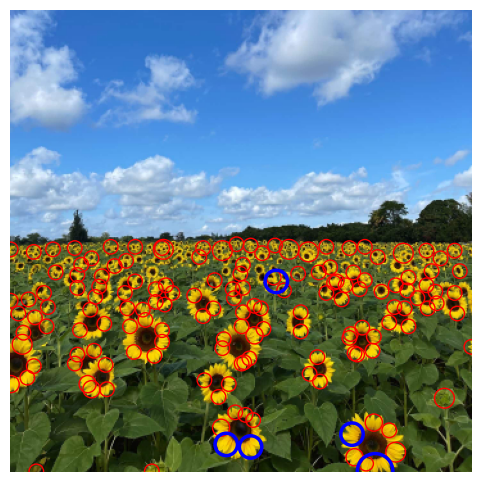

In [65]:
im = cv.imread('a2images/the_berry_farms_sunflower_field.jpeg', cv.IMREAD_REDUCED_COLOR_4)
b, g, r = [im[:,:,k].astype(np.float32)/255 for k in range(3)]
gray = np.clip(r-b, 0, 1) # did this to enhance sunflowers in the image and surpress clouds

sigma_min = 4; sigma_max = 25; n_scales = 30; 
sigmas = np.linspace(sigma_min, sigma_max, n_scales)
stack = []

for s in sigmas:
    g = cv.GaussianBlur(gray, (0, 0), s)
    stack.append((s**2) * cv.Laplacian(g, cv.CV_32F)) #since LoG is sigma^2 * Laplacian(Gaussian)

stack = np.stack(stack)
resp = -stack #as from before all dark blobs are now clouds due to plane substraction I chose bright blobs

thr = 0.25*resp.max()
nms = (resp == maximum_filter(resp, size=(3, 3, 3))) & (resp >= thr)
si, xs, ys = np.nonzero(nms)

blobs = [(xs_, ys_, np.sqrt(2)*sigmas[i], sigmas[i], resp[i, xs_, ys_])
         for i, xs_, ys_ in zip(si, xs, ys)]

blobs = drop_clusters(blobs)
blobs.sort(key=lambda b: -b[2])

print(f"sigma range: {sigma_min} - {sigma_max}, number of scales: {n_scales}")
print(f"Number of detected blobs: {len(blobs)}")
print("largest 5 blobs (x, y, radius, sigma, response):")
for x, y, r, s, _ in blobs[:5]:
    print(f"  ({x}, {y}, {r:.2f}, {s:.2f})")

fig, ax = plt.subplots(figsize=(10, 6))
ax.imshow(cv.cvtColor(im, cv.COLOR_BGR2RGB))

for x, y, r, s, *_ in blobs:
    ax.add_patch(plt.Circle((y, x), r, color='red', fill=False, lw=1))

for x, y, r, s, *_ in blobs[:5]: #top 5
    ax.add_patch(plt.Circle((y, x), r, color='blue', fill=False, lw=2.5))

ax.axis('off'); plt.show()
